# 01_pilot.ipynb — Detach-Hydra: pilot test of group-level pruning for HYDRA

**Author:** Shreed

**Notebook:** `02_detach_hydra/notebooks/01_pilot.ipynb` (pilot; extends `01_reproduction/notebooks/01_hydra_baseline.ipynb`).

**Idea.** Detach-ROCKET prunes ROCKET features that contribute little to the linear classifier. This notebook tests a Hydra version of that idea, **Detach-Hydra**:

1. Fit the full Hydra transform (k=8, g=64) and a ridge classifier.
2. Score each **kernel group** by the size of its ridge coefficients, then repeatedly remove the weakest groups, using the training data only.
3. **Rebuild a smaller Hydra transform** that only convolves the groups we kept, so the pruned model is genuinely cheaper at test time, not just a column mask.

This is a **quick pilot** on 9 small or medium UCR datasets × 3 seeds. Its job is to decide whether the idea is worth scaling to 40 or 112 datasets.

**Correctness first.** Our team has already found five "improvements" that turned out to be bugs. So the notebook runs equivalence tests (Section 3), and they must print `PASS` before any results are computed. The pilot loop also asserts, for every model it rebuilds, that the rebuilt transform reproduces the kept columns of the full transform.

## Why prune whole groups, not single kernels

From `hydra-authors-repo/code/hydra.py`, `forward()` works like this:

- **Blocks.** For each dilation `d` and each `diff_index` (0 = raw `X`, 1 = `torch.diff(X)`), it convolves with `W[d, diff_index]` (`k·h` kernels). It then reshapes the output to `(n, h, k, T)`: `h = g / 2` groups of `k = 8` kernels.
- **Max part (soft).** At every time step, it finds the **argmax over the k kernels of one group**. `count_max` adds up the winning *values* (`scatter_add` of `max_values`).
- **Min part (hard).** It also finds the argmin over the same k kernels. `count_min` adds up *ones*, so it is a hard count.
- **Order.** It appends `count_max` and then `count_min`, each of shape `(n, h, k)`. It concatenates everything along dim 1 and flattens.

So kernels **only compete inside their own group**. That has two consequences:

- **Removing a whole group is exact.** Every other group's features stay bit-for-bit the same, so we can delete that group's convolutions and get a real speed-up.
- **Removing a single kernel is not.** It changes which kernel wins at each time step in its group, which changes that group's other 15 features. Detach-ROCKET's per-feature pruning therefore does **not** carry over directly to Hydra.

A group is the triple `(dilation index d, diff_index, group j)`. With the defaults there are `num_dilations × 2 × 32` groups, and each one owns `2k = 16` features (8 soft-max, 8 hard-min).

**Feature layout (derived from the source, checked by Test 2).**

- Blocks come in `(d, diff_index)` order, with block number `b = d·divisor + diff_index`.
- Each block holds `2·h·k` columns, so it starts at `base = b·2hk`, and inside it the layout is `[max: h groups × k][min: h groups × k]`.
- Group `j` therefore owns two column ranges:
  - max part: `base + j·k … base + (j+1)·k − 1`
  - min part: `base + h·k + j·k … base + h·k + (j+1)·k − 1`

## 1. Setup

In [1]:
# Project paths (same conventions as 01_reproduction/notebooks/01_hydra_baseline.ipynb)
from pathlib import Path
import sys

# Repository root = the folder that contains hydra-authors-repo/ (works from any working directory)
ROOT = Path.cwd().resolve()
while not (ROOT / "hydra-authors-repo").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Run this notebook from inside the hydra-time-series-project repository.")
    ROOT = ROOT.parent

HYDRA_CODE  = ROOT / "hydra-authors-repo" / "code"
AUTHORS_RES = ROOT / "hydra-authors-repo" / "results"
RESULTS_DIR = ROOT / "02_detach_hydra" / "results"
FIG_DIR     = RESULTS_DIR / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(HYDRA_CODE))

PROJECT_DIR = ROOT
DATA_DIR = ROOT / "data" / "ucr_tsml"          # git-ignored; aeon downloads any missing dataset here
# read only; written by 01_reproduction/notebooks/01_hydra_baseline.ipynb (run that first)
BASELINE_CSV = ROOT / "01_reproduction" / "results" / "hydra_default_baseline.csv"

# New output files only (no existing result file is overwritten)
PILOT_CSV = RESULTS_DIR / "detach_hydra_pilot.csv"
PATHS_CSV = RESULTS_DIR / "detach_hydra_pilot_paths.csv"
KEPT_CSV = RESULTS_DIR / "detach_hydra_pilot_kept_groups.csv"

print("Project directory:", PROJECT_DIR.resolve())
print("Dataset directory:", DATA_DIR.resolve())
print("Results directory:", RESULTS_DIR.resolve())

Project directory: /Users/shreed/PROJECTS/Hydra_1
Dataset directory: /Users/shreed/PROJECTS/Hydra_1/data/ucr_tsml
Results directory: /Users/shreed/PROJECTS/Hydra_1/results/Shreed


In [2]:
import importlib.util
import math
import random
import sys
import time
import traceback
import warnings
from time import perf_counter

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from aeon.datasets import load_classification
from sklearn.linear_model import RidgeClassifier, RidgeClassifierCV
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_score

warnings.filterwarnings("ignore", message="The least populated class")
# Ridge with a small alpha (1e-3, the grid edge) on n_train << n_features gives a near-singular
# Gram matrix (many all-zero / duplicated sparse Hydra features). sklearn then warns and falls back
# to a least-squares solve. These are warnings, not errors - results are still computed.
from scipy.linalg import LinAlgWarning
warnings.filterwarnings("ignore", category=LinAlgWarning)
warnings.filterwarnings("ignore", message="Singular matrix in solving dual problem")

print("numpy", np.__version__, "| pandas", pd.__version__, "| torch", torch.__version__)

numpy 2.3.5 | pandas 3.0.6 | torch 2.15.0


In [3]:
# Experiment configuration (one place to change for the scale-up)
PILOT_DATASETS = [
    "ECG200", "Beef", "Lightning7", "CricketX", "Adiac",
    "MedicalImages", "SwedishLeaf", "InsectWingbeatSound", "Computers",
]
SEEDS = [0, 1, 2]

K, G = 8, 64                          # Hydra defaults
ALPHAS = np.logspace(-3, 3, 10)       # team-wide ridge alpha grid
BATCH_SIZE = 256

PRUNE_FRACTION = 0.10                 # remove the weakest 10% of active groups per step
MIN_KEEP_FRACTION = 0.05              # stop at 5% of groups ...
MIN_KEEP_GROUPS = 4                   # ... but never fewer than 4
CV_TOLERANCE = 0.005                  # selection rule: smallest set within 0.005 of best CV acc
RETENTION_LEVELS = {"detach_50": 0.50, "detach_25": 0.25, "detach_10": 0.10}
N_RANDOM_DRAWS = 5                    # random-pruning control
TIMING_REPEATS = 3                    # median of 3 after one warm-up call


def set_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

In [4]:
# Import the authors' Hydra BY FILE PATH (a pip package called `hydra` may shadow `import hydra`)
HYDRA_SOURCE = HYDRA_CODE / "hydra.py"
assert HYDRA_SOURCE.exists(), f"Missing official implementation: {HYDRA_SOURCE}"

spec = importlib.util.spec_from_file_location("hydra_official_impl", HYDRA_SOURCE)
hydra_module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = hydra_module
spec.loader.exec_module(hydra_module)

Hydra = hydra_module.Hydra
SparseScaler = hydra_module.SparseScaler

# Check the attribute names this notebook relies on
_probe = Hydra(96, k=K, g=G, seed=0)
for attr in ["k", "g", "h", "divisor", "dilations", "num_dilations", "paddings", "W"]:
    assert hasattr(_probe, attr), f"Official Hydra has no attribute '{attr}'"
assert _probe.W.shape == (_probe.num_dilations, _probe.divisor, _probe.k * _probe.h, 1, 9)
print("Hydra loaded from:", HYDRA_SOURCE.resolve())
print("Example (L=96): dilations =", _probe.dilations.tolist(),
      "| divisor =", _probe.divisor, "| h =", _probe.h, "| W shape =", tuple(_probe.W.shape))
del _probe

Hydra loaded from: /Users/shreed/PROJECTS/Hydra_1/hydra-authors-repo/code/hydra.py
Example (L=96): dilations = [1, 2, 4, 8] | divisor = 2 | h = 32 | W shape = (4, 2, 256, 1, 9)


In [5]:
# Dataset loader (identical checks to 01_reproduction/notebooks/01_hydra_baseline.ipynb: default UCR split, float32, string labels)
def load_ucr_dataset(dataset_name, extract_path=DATA_DIR):
    X_train, y_train = load_classification(
        name=dataset_name, split="train", extract_path=str(extract_path), return_metadata=False
    )
    X_test, y_test = load_classification(
        name=dataset_name, split="test", extract_path=str(extract_path), return_metadata=False
    )
    X_train = np.asarray(X_train, dtype=np.float32)
    X_test = np.asarray(X_test, dtype=np.float32)
    y_train = np.asarray(y_train).astype(str)
    y_test = np.asarray(y_test).astype(str)

    if X_train.ndim != 3 or X_test.ndim != 3:
        raise ValueError(f"{dataset_name}: expected 3D arrays")
    if X_train.shape[1] != 1 or X_test.shape[1] != 1:
        raise ValueError(f"{dataset_name}: expected univariate data")
    if X_train.shape[2] != X_test.shape[2]:
        raise ValueError(f"{dataset_name}: train/test lengths differ")
    if not set(np.unique(y_test)).issubset(set(np.unique(y_train))):
        raise ValueError(f"{dataset_name}: test labels include unseen classes")
    return X_train, y_train, X_test, y_test


def to_tensor(X):
    return torch.as_tensor(np.ascontiguousarray(X), dtype=torch.float32)

## 2. Implementation

### 2a. Group → column mapping

`group_feature_index(hydra)` returns an integer array of shape `(num_dilations, divisor, h, 2k)`. Entry `[d, v, j]` lists the column indices of group `(d, v, j)`'s 16 features in the full Hydra feature matrix: the first `k` are its max (soft) features and the last `k` its min (hard) features. The **flat group id** is `(d·divisor + v)·h + j`, which is the order of `group_feature_index(hydra).reshape(-1, 2k)`.

`kept_columns(hydra, keep_mask)` lists the full-matrix columns in **exactly the order `PrunedHydra` outputs them**. For each `(d, v)` block that has kept groups, it lists the max columns of those groups (in `j` order) and then their min columns.

### 2b. `PrunedHydra` and `MaxOnlyHydra`

`PrunedHydra(full_hydra, keep_mask)`:

- `keep_mask` has shape `(num_dilations, divisor, h)`.
- For each `(d, diff_index)` block it stores only the weight rows `j·k … (j+1)·k − 1` of the kept groups `j`. These are the **original** weights, with the same dilation and padding as the full model.
- Blocks with no kept group are skipped, so no convolution runs for them.
- `forward()` is a line-by-line copy of the official forward with `h` replaced by `h_kept`.

`MaxOnlyHydra` is a reference model that keeps all convolutions but only the soft-max features.

In [6]:
def group_feature_index(hydra):
    # (num_dilations, divisor, h, 2k) column indices into the full Hydra feature matrix.
    k, h, D, V = hydra.k, hydra.h, hydra.num_dilations, hydra.divisor
    idx = np.empty((D, V, h, 2 * k), dtype=np.int64)
    ar = np.arange(k)
    for d in range(D):
        for v in range(V):
            base = (d * V + v) * 2 * h * k
            for j in range(h):
                idx[d, v, j, :k] = base + j * k + ar              # max (soft) part
                idx[d, v, j, k:] = base + h * k + j * k + ar      # min (hard) part
    return idx


def kept_columns(hydra, keep_mask):
    # Full-matrix columns, in the exact order PrunedHydra(hydra, keep_mask) produces them.
    keep_mask = np.asarray(keep_mask, dtype=bool)
    gi = group_feature_index(hydra)
    k = hydra.k
    cols = []
    for d in range(hydra.num_dilations):
        for v in range(hydra.divisor):
            js = np.flatnonzero(keep_mask[d, v])
            if len(js) == 0:
                continue
            cols.append(gi[d, v, js, :k].ravel())   # max block of the kept groups
            cols.append(gi[d, v, js, k:].ravel())   # then min block of the kept groups
    return np.concatenate(cols) if cols else np.empty(0, dtype=np.int64)


def max_columns(hydra):
    # Columns of all max (soft) features, in full-matrix order.
    gi = group_feature_index(hydra)
    return gi[..., : hydra.k].reshape(hydra.num_dilations * hydra.divisor, -1).ravel()


def group_table(hydra):
    # One row per group in flat-id order: (flat_id, dilation_index, dilation, diff_index, group).
    rows = []
    for d in range(hydra.num_dilations):
        for v in range(hydra.divisor):
            for j in range(hydra.h):
                rows.append({
                    "flat_id": (d * hydra.divisor + v) * hydra.h + j,
                    "dilation_index": d,
                    "dilation": int(hydra.dilations[d].item()),
                    "diff_index": v,
                    "group": j,
                })
    return pd.DataFrame(rows)


class PrunedHydra(nn.Module):
    # Hydra transform that only convolves the kept groups of `full_hydra`.
    # Uses the ORIGINAL weights (no resampling) and the same dilations and paddings.
    # (d, diff_index) blocks with no kept group are skipped entirely (no convolution).

    def __init__(self, full_hydra, keep_mask):
        super().__init__()
        keep_mask = np.asarray(keep_mask, dtype=bool)
        expected = (full_hydra.num_dilations, full_hydra.divisor, full_hydra.h)
        assert keep_mask.shape == expected, f"keep_mask shape {keep_mask.shape} != {expected}"
        assert keep_mask.any(), "keep_mask keeps no groups"

        self.k = full_hydra.k
        self.divisor = full_hydra.divisor
        self.keep_mask = keep_mask.copy()
        self.blocks = []   # (diff_index, dilation, padding, h_kept, W_slice)

        k = self.k
        for d in range(full_hydra.num_dilations):
            dil = int(full_hydra.dilations[d].item())
            pad = int(full_hydra.paddings[d].item())
            for v in range(full_hydra.divisor):
                js = np.flatnonzero(keep_mask[d, v])
                if len(js) == 0:
                    continue
                rows = torch.as_tensor((js[:, None] * k + np.arange(k)[None, :]).ravel(), dtype=torch.long)
                W = full_hydra.W[d, v].index_select(0, rows).clone().contiguous()   # (h_kept*k, 1, 9)
                self.blocks.append((v, dil, pad, len(js), W))

        self.needs_diff = any(b[0] == 1 for b in self.blocks)
        self.n_groups_kept = int(keep_mask.sum())
        self.n_kernels = self.n_groups_kept * k
        self.n_features = 2 * self.n_kernels

    @property
    def weight_bytes(self):
        return sum(W.numel() * W.element_size() for (_, _, _, _, W) in self.blocks)

    def batch(self, X, batch_size=256):
        num_examples = X.shape[0]
        if num_examples <= batch_size:
            return self(X)
        Z = []
        for batch in torch.arange(num_examples).split(batch_size):
            Z.append(self(X[batch]))
        return torch.cat(Z)

    def forward(self, X):
        num_examples = X.shape[0]
        if self.needs_diff:
            diff_X = torch.diff(X)
        Z = []
        for (v, dil, pad, h_kept, W) in self.blocks:
            _Z = F.conv1d(X if v == 0 else diff_X, W, dilation=dil, padding=pad) \
                  .view(num_examples, h_kept, self.k, -1)

            max_values, max_indices = _Z.max(2)
            count_max = torch.zeros(num_examples, h_kept, self.k)

            min_values, min_indices = _Z.min(2)
            count_min = torch.zeros(num_examples, h_kept, self.k)

            count_max.scatter_add_(-1, max_indices, max_values)
            count_min.scatter_add_(-1, min_indices, torch.ones_like(min_values))

            Z.append(count_max)
            Z.append(count_min)
        return torch.cat(Z, 1).view(num_examples, -1)


class MaxOnlyHydra(nn.Module):
    # Reference: same convolutions as full Hydra, but only the max (soft) features are kept
    # (the argmin / hard-count step is skipped).

    def __init__(self, full_hydra):
        super().__init__()
        self.full = full_hydra
        self.k, self.h, self.divisor = full_hydra.k, full_hydra.h, full_hydra.divisor
        self.n_kernels = full_hydra.num_dilations * full_hydra.divisor * full_hydra.h * full_hydra.k
        self.n_features = self.n_kernels

    @property
    def weight_bytes(self):
        return self.full.W.numel() * self.full.W.element_size()

    def batch(self, X, batch_size=256):
        num_examples = X.shape[0]
        if num_examples <= batch_size:
            return self(X)
        return torch.cat([self(X[b]) for b in torch.arange(num_examples).split(batch_size)])

    def forward(self, X):
        hy = self.full
        num_examples = X.shape[0]
        if self.divisor > 1:
            diff_X = torch.diff(X)
        Z = []
        for dilation_index in range(hy.num_dilations):
            d = hy.dilations[dilation_index].item()
            p = hy.paddings[dilation_index].item()
            for diff_index in range(self.divisor):
                _Z = F.conv1d(X if diff_index == 0 else diff_X, hy.W[dilation_index, diff_index],
                              dilation=d, padding=p).view(num_examples, self.h, self.k, -1)
                max_values, max_indices = _Z.max(2)
                count_max = torch.zeros(num_examples, self.h, self.k)
                count_max.scatter_add_(-1, max_indices, max_values)
                Z.append(count_max)
        return torch.cat(Z, 1).view(num_examples, -1)


def n_kernels_of(model):
    if isinstance(model, (PrunedHydra, MaxOnlyHydra)):
        return model.n_kernels
    return model.num_dilations * model.divisor * model.h * model.k


def weight_bytes_of(model):
    if isinstance(model, (PrunedHydra, MaxOnlyHydra)):
        return model.weight_bytes
    return model.W.numel() * model.W.element_size()


def transform(model, X_tensor, batch_size=BATCH_SIZE):
    with torch.inference_mode():
        return model.batch(X_tensor, batch_size=batch_size)


def assert_same(a, b, name):
    # Exact equality preferred, allclose(atol=1e-6) accepted. Returns which one held.
    assert a.shape == b.shape, f"{name}: shape {tuple(a.shape)} != {tuple(b.shape)}"
    if torch.equal(a, b):
        return "equal"
    max_abs = (a - b).abs().max().item()
    assert torch.allclose(a, b, atol=1e-6, rtol=0), f"{name}: NOT equivalent, max |diff| = {max_abs:.3e}"
    return f"allclose (max |diff| {max_abs:.1e})"

## 3. Equivalence tests (must all PASS before any result is reported)

| Test | What it checks |
|---|---|
| 1 | `PrunedHydra` with every group kept gives exactly the official `Hydra` output (ECG200, L=96, and Beef, L=470) |
| 2 | For 5 random masks (~10/30/50/70/90% kept) and 2 edge-case masks, `PrunedHydra(X) == Hydra(X)[:, kept_columns]`. This proves the column map and the rebuilt transform. |
| 3 | Feature and kernel counts are `2k × kept groups` and `k × kept groups` |
| 4 | Fitting `SparseScaler` on the kept columns gives the same values as fitting it on all columns and then subsetting |
| 5 | The official Hydra on ECG200 (seed 0) reproduces `01_reproduction/notebooks/01_hydra_baseline.ipynb`'s baseline accuracy (0.87) |
| 6 (extra) | `MaxOnlyHydra(X) == Hydra(X)[:, max_columns]` |

In [7]:
# Load the two test datasets once
TEST_DATA = {}
for name in ["ECG200", "Beef"]:
    Xtr, ytr, Xte, yte = load_ucr_dataset(name)
    TEST_DATA[name] = (to_tensor(Xtr), ytr, to_tensor(Xte), yte)
    print(f"{name}: train {Xtr.shape}, test {Xte.shape}")

# ---- Test 1: all groups kept == official Hydra ----
for name, (Xtr_t, ytr, Xte_t, yte) in TEST_DATA.items():
    full = Hydra(Xtr_t.shape[-1], k=K, g=G, seed=0)
    pruned_all = PrunedHydra(full, np.ones((full.num_dilations, full.divisor, full.h), dtype=bool))
    r_tr = assert_same(transform(pruned_all, Xtr_t), transform(full, Xtr_t), f"Test 1 {name} train")
    r_te = assert_same(transform(pruned_all, Xte_t), transform(full, Xte_t), f"Test 1 {name} test")
    print(f"  {name}: train {r_tr}, test {r_te}")
print("Test 1 PASS: PrunedHydra(all groups kept) reproduces the official Hydra output")

ECG200: train (100, 1, 96), test (100, 1, 96)
Beef: train (30, 1, 470), test (30, 1, 470)
  ECG200: train equal, test equal
  Beef: train equal, test equal
Test 1 PASS: PrunedHydra(all groups kept) reproduces the official Hydra output


In [8]:
# ---- Test 2: random masks -> PrunedHydra(X) == full(X)[:, kept_columns] ----
# ---- Test 3: kernel / feature counts ----
rng = np.random.default_rng(12345)
for name, (Xtr_t, ytr, Xte_t, yte) in TEST_DATA.items():
    full = Hydra(Xtr_t.shape[-1], k=K, g=G, seed=0)
    Z_full = transform(full, Xtr_t)
    shape = (full.num_dilations, full.divisor, full.h)

    masks = {}
    for frac in [0.10, 0.30, 0.50, 0.70, 0.90]:
        m = rng.random(shape) < frac
        if not m.any():
            m.flat[rng.integers(m.size)] = True
        masks[f"random ~{int(frac * 100)}%"] = m
    # Edge cases: whole (d, diff) blocks empty, and raw-only / diff-only models
    m = rng.random(shape) < 0.5; m[0, 1, :] = False; m[-1, 0, :] = False
    masks["empty blocks"] = m
    m = np.zeros(shape, dtype=bool); m[:, 1, ::3] = True
    masks["diff-only"] = m

    for label, mask in masks.items():
        pruned = PrunedHydra(full, mask)
        cols = kept_columns(full, mask)
        Z_p = transform(pruned, Xtr_t)
        res = assert_same(Z_p, Z_full[:, cols], f"Test 2 {name} {label}")
        # Test 3
        n_kept = int(mask.sum())
        assert pruned.n_features == 2 * K * n_kept == Z_p.shape[1] == len(cols), "Test 3 feature count"
        assert pruned.n_kernels == K * n_kept, "Test 3 kernel count"
        assert sum(W.shape[0] for (*_, W) in pruned.blocks) == K * n_kept, "Test 3 weight rows"
        assert len(np.unique(cols)) == len(cols), "duplicate columns in kept_columns"
        print(f"  {name:6s} {label:14s} groups kept {n_kept:4d}/{mask.size} -> {res}")

print("Test 2 PASS: rebuilt PrunedHydra == full Hydra features[:, kept_columns] for every mask")
print("Test 3 PASS: n_features == 2k * kept groups, n_kernels == k * kept groups")

  ECG200 random ~10%    groups kept   24/256 -> equal
  ECG200 random ~30%    groups kept   77/256 -> equal
  ECG200 random ~50%    groups kept  131/256 -> equal
  ECG200 random ~70%    groups kept  182/256 -> equal
  ECG200 random ~90%    groups kept  232/256 -> equal
  ECG200 empty blocks   groups kept   96/256 -> equal
  ECG200 diff-only      groups kept   44/256 -> equal
  Beef   random ~10%    groups kept   25/384 -> equal
  Beef   random ~30%    groups kept  116/384 -> equal
  Beef   random ~50%    groups kept  195/384 -> equal
  Beef   random ~70%    groups kept  272/384 -> equal
  Beef   random ~90%    groups kept  347/384 -> equal
  Beef   empty blocks   groups kept  157/384 -> equal
  Beef   diff-only      groups kept   66/384 -> equal
Test 2 PASS: rebuilt PrunedHydra == full Hydra features[:, kept_columns] for every mask
Test 3 PASS: n_features == 2k * kept groups, n_kernels == k * kept groups


In [9]:
# ---- Test 4: SparseScaler fitted on kept columns == fitted on all columns then subset ----
for name, (Xtr_t, ytr, Xte_t, yte) in TEST_DATA.items():
    full = Hydra(Xtr_t.shape[-1], k=K, g=G, seed=0)
    Ztr, Zte = transform(full, Xtr_t), transform(full, Xte_t)
    mask = np.random.default_rng(7).random((full.num_dilations, full.divisor, full.h)) < 0.3
    cols = torch.as_tensor(kept_columns(full, mask))

    s_all = SparseScaler()
    A_tr = s_all.fit_transform(Ztr)[:, cols]
    A_te = s_all.transform(Zte)[:, cols]
    s_sub = SparseScaler()
    B_tr = s_sub.fit_transform(Ztr[:, cols])
    B_te = s_sub.transform(Zte[:, cols])
    assert torch.allclose(A_tr, B_tr, atol=1e-6) and torch.allclose(A_te, B_te, atol=1e-6), f"Test 4 {name}"
    print(f"  {name}: max |diff| train {(A_tr - B_tr).abs().max().item():.1e}, "
          f"test {(A_te - B_te).abs().max().item():.1e}")
print("Test 4 PASS: scaling once and subsetting columns == refitting the scaler on the kept columns")

  ECG200: max |diff| train 0.0e+00, test 0.0e+00
  Beef: max |diff| train 0.0e+00, test 0.0e+00
Test 4 PASS: scaling once and subsetting columns == refitting the scaler on the kept columns


In [10]:
# ---- Test 6 (extra): MaxOnlyHydra == full[:, max_columns] ----
for name, (Xtr_t, ytr, Xte_t, yte) in TEST_DATA.items():
    full = Hydra(Xtr_t.shape[-1], k=K, g=G, seed=0)
    res = assert_same(transform(MaxOnlyHydra(full), Xtr_t),
                      transform(full, Xtr_t)[:, max_columns(full)], f"Test 6 {name}")
    print(f"  {name}: {res}")
print("Test 6 PASS: MaxOnlyHydra == full Hydra max columns")

  ECG200: equal
  Beef: equal
Test 6 PASS: MaxOnlyHydra == full Hydra max columns


### Shared pipeline helper

`fit_eval` runs the `01_reproduction/notebooks/01_hydra_baseline.ipynb` pipeline unchanged: transform, then `SparseScaler` fitted on train only, then `RidgeClassifierCV(np.logspace(-3, 3, 10))`, then predict. With `time_it=True` it also returns the timings (one warm-up call, then the median of 3 runs) and the model size, measured as Hydra weights plus ridge `coef_` and `intercept_` in bytes.

In [11]:
def timed(fn, repeats=TIMING_REPEATS):
    fn()                                   # warm-up
    times, out = [], None
    for _ in range(repeats):
        t0 = perf_counter()
        out = fn()
        times.append(perf_counter() - t0)
    return out, float(np.median(times))


def alpha_at_edge(alpha):
    return bool(np.isclose(alpha, ALPHAS[0]) or np.isclose(alpha, ALPHAS[-1]))


def fit_eval(model, Xtr_t, ytr, Xte_t, yte, time_it=False):
    # Transform -> SparseScaler -> RidgeClassifierCV, exactly as in 01_reproduction/notebooks/01_hydra_baseline.ipynb.
    if time_it:
        Ztr, t_train = timed(lambda: transform(model, Xtr_t))
        Zte, t_test = timed(lambda: transform(model, Xte_t))
    else:
        t0 = perf_counter(); Ztr = transform(model, Xtr_t); t_train = perf_counter() - t0
        t0 = perf_counter(); Zte = transform(model, Xte_t); t_test = perf_counter() - t0

    scaler = SparseScaler()
    Ztr_s = scaler.fit_transform(Ztr).detach().cpu().numpy()
    Zte_s = scaler.transform(Zte).detach().cpu().numpy()

    clf = RidgeClassifierCV(alphas=ALPHAS).fit(Ztr_s, ytr)
    pred = clf.predict(Zte_s)

    latency_ms = np.nan
    if time_it:
        # latency = (median test transform time + median scale-and-predict time) / n_test.
        # The transform was already timed above, so it is not repeated here (halves the run time).
        _, t_scale_predict = timed(lambda: clf.predict(scaler.transform(Zte).detach().cpu().numpy()))
        latency_ms = 1000.0 * (t_test + t_scale_predict) / len(yte)

    res = {
        "n_kernels": n_kernels_of(model),
        "n_features": int(Ztr.shape[1]),
        "alpha": float(clf.alpha_),
        "alpha_at_edge": alpha_at_edge(clf.alpha_),
        "test_acc": accuracy_score(yte, pred),
        "macro_f1": f1_score(yte, pred, average="macro", zero_division=0),
        "train_transform_s": t_train,
        "test_transform_s": t_test,
        "latency_ms_per_series": latency_ms,
        "model_bytes": int(weight_bytes_of(model) + clf.coef_.nbytes + clf.intercept_.nbytes),
    }
    return res, Ztr, Zte

In [12]:
# ---- Test 5: official Hydra on ECG200, seed 0, reproduces 01_reproduction/notebooks/01_hydra_baseline.ipynb ----
Xtr_t, ytr, Xte_t, yte = TEST_DATA["ECG200"]
res5, _, _ = fit_eval(Hydra(Xtr_t.shape[-1], k=K, g=G, seed=0), Xtr_t, ytr, Xte_t, yte)

baseline = pd.read_csv(BASELINE_CSV)
expected = float(baseline.loc[(baseline["dataset"] == "ECG200") & (baseline["seed"] == 0), "accuracy"].iloc[0])
print(f"  ECG200 seed 0: this notebook {res5['test_acc']:.4f} | Notebook 1 {expected:.4f} | alpha {res5['alpha']:.4g}")
assert abs(res5["test_acc"] - expected) < 1e-9, "Pipeline does not reproduce Notebook 1"
assert abs(expected - 0.87) < 1e-9
print("Test 5 PASS: pipeline reproduces the Notebook 1 baseline (0.87)")

print("\n=== ALL EQUIVALENCE TESTS PASSED ===")

  ECG200 seed 0: this notebook 0.8700 | Notebook 1 0.8700 | alpha 215.4
Test 5 PASS: pipeline reproduces the Notebook 1 baseline (0.87)

=== ALL EQUIVALENCE TESTS PASSED ===


## 4. Sequential group detachment (training data only)

For one dataset and seed:

1. Fit the full `Hydra(L, k=8, g=64, seed)`, transform train and test, and fit `SparseScaler` on the train features only.
2. Choose ridge alpha **once** with `RidgeClassifierCV(logspace(-3, 3, 10))` on the full scaled train features. Record whether it sits at a grid edge.
3. Iterate with that **fixed alpha** (`RidgeClassifier(alpha)`), starting with all groups active:
   - Fit ridge on the active groups' training columns.
   - **Group score** = L2 norm of `coef_` over the group's 16 columns and all classes.
   - **Selection score** = stratified k-fold CV accuracy on the *training set*, with `n_splits = min(5, smallest class count)` and at least 2.
   - Test accuracy at each step is recorded **for plotting only**. It is never used for any choice. Random pruning at the same size (5 draws) is recorded the same way, also for plotting only.
   - Remove the weakest 10% of active groups (at least 1). Stop when 5% of groups (at least 4) remain.
4. **Selected model:** the smallest active set whose CV accuracy is within 0.005 of the best CV accuracy along the path.
5. **Rebuild:** build `PrunedHydra(selected mask)`, re-transform train and test **from raw data**, refit `SparseScaler` and `RidgeClassifierCV`, and evaluate. This is the deployed Detach-Hydra. Every rebuild also asserts that the pruned features equal the full features' kept columns.
6. **Fixed retention levels** (50%, 25% and 10% of groups) are taken from the importance ranking implied by the path: groups eliminated later rank higher, and the survivors are ordered by their final score. They are rebuilt the same way, which gives curves that do not depend on the selection rule.

**Known small leak (acceptable for a pilot).** Inside the CV loop, the `SparseScaler` statistics come from the full training set, including each fold's validation part. The test set is never involved.

In [13]:
def detach_path(Ztr_s, ytr, Zte_s, yte, gi_flat, alpha, seed):
    # Sequential group elimination with a fixed ridge alpha. Uses ytr / Ztr_s for every decision;
    # Zte_s / yte are only used to record plot-only curves.
    n_groups, two_k = gi_flat.shape
    min_groups = max(MIN_KEEP_GROUPS, int(math.ceil(MIN_KEEP_FRACTION * n_groups)))

    _, class_counts = np.unique(ytr, return_counts=True)
    n_splits = max(2, min(5, int(class_counts.min())))
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    rng = np.random.default_rng(10_000 + seed)

    active = np.arange(n_groups)
    eliminated = []          # least important first
    path, active_sets = [], []
    step = 0
    while True:
        cols = gi_flat[active].ravel()
        Xa = Ztr_s[:, cols]

        clf = RidgeClassifier(alpha=alpha).fit(Xa, ytr)
        # sklearn returns coef_ as (n_features,) for binary problems and (n_classes, n_features)
        # otherwise; atleast_2d makes both (n_rows, n_features) before splitting into groups.
        coef = np.atleast_2d(clf.coef_)
        assert coef.shape[1] == len(active) * two_k, f"coef_ shape {clf.coef_.shape} vs {len(active)} groups"
        coef = coef.reshape(coef.shape[0], len(active), two_k)              # (n_rows, groups, 2k)
        scores = np.sqrt((coef.astype(np.float64) ** 2).sum(axis=(0, 2)))

        cv_acc = cross_val_score(RidgeClassifier(alpha=alpha), Xa, ytr, cv=cv, scoring="accuracy").mean()

        # ---- plot-only quantities (never used for selection) ----
        test_acc_plot = clf.score(Zte_s[:, cols], yte)
        rand_accs = []
        for _ in range(N_RANDOM_DRAWS):
            rg = np.sort(rng.choice(n_groups, size=len(active), replace=False))
            rc = gi_flat[rg].ravel()
            rand_accs.append(RidgeClassifier(alpha=alpha).fit(Ztr_s[:, rc], ytr).score(Zte_s[:, rc], yte))

        path.append({
            "step": step,
            "groups_active": len(active),
            "frac_groups_kept": len(active) / n_groups,
            "cv_acc": cv_acc,
            "cv_n_splits": n_splits,
            "test_acc_for_plot_only": test_acc_plot,
            "random_test_acc_for_plot_only": float(np.mean(rand_accs)),
        })
        active_sets.append(active.copy())

        if len(active) <= min_groups:
            final_order = active[np.argsort(-scores, kind="stable")]   # most important first
            break

        n_remove = max(1, int(math.floor(PRUNE_FRACTION * len(active))))
        n_remove = min(n_remove, len(active) - min_groups)
        order = np.argsort(scores, kind="stable")                      # weakest first
        eliminated.extend(active[order[:n_remove]].tolist())
        active = np.sort(active[order[n_remove:]])
        step += 1

    importance_rank = np.concatenate([final_order, np.array(eliminated[::-1], dtype=np.int64)])
    assert len(importance_rank) == n_groups and len(np.unique(importance_rank)) == n_groups

    path = pd.DataFrame(path)
    best = path["cv_acc"].max()
    eligible = path[path["cv_acc"] >= best - CV_TOLERANCE]
    sel_step = int(eligible.sort_values(["groups_active", "cv_acc"], ascending=[True, False]).iloc[0]["step"])
    path["selected"] = path["step"] == sel_step
    return path, active_sets[sel_step], importance_rank, float(path.loc[sel_step, "cv_acc"])

## 5. Controls

Each control is compared at the same number of kept groups as the selected Detach model:

- **`random_same_size`.** Keep the same number of groups, chosen uniformly at random (5 draws; accuracy is the mean, timing comes from draw 0). If Detach does not beat this, the importance ranking adds nothing.
- **`small_g`.** A fresh `Hydra` with `g' = max(2, 2·round(64·frac_kept/2))`, which gives roughly the same number of kernels (g' must be even because half the groups use the difference). If Detach does not beat this, "pruning" is just a roundabout way of choosing a smaller `g`. **This is the control that decides whether the idea is a contribution or only a hyperparameter change.**
- **`full`.** Hydra with k=8 and g=64, the reference.
- **`max_only`.** The same convolutions with the min (hard-count) block dropped. It halves the features but removes no convolutions.

**Timing.** The pilot loop runs with `torch.set_num_threads(1)`, because the paper's speed claims are single-core. Each timed quantity is the median of 3 runs after one warm-up call.

In [14]:
def run_one(dataset, seed):
    Xtr, ytr, Xte, yte = load_ucr_dataset(dataset)
    Xtr_t, Xte_t = to_tensor(Xtr), to_tensor(Xte)
    L = Xtr.shape[-1]

    set_seeds(seed)
    full = Hydra(L, k=K, g=G, seed=seed)
    gi_flat = group_feature_index(full).reshape(-1, 2 * K)
    n_groups = gi_flat.shape[0]
    mask_shape = (full.num_dilations, full.divisor, full.h)
    n_kernels_full = n_kernels_of(full)

    t_run = perf_counter()
    def stage(msg):
        print(f"      {dataset} seed {seed}: {msg} ({perf_counter() - t_run:.1f}s)", flush=True)

    common = {"dataset": dataset, "seed": seed, "series_length": L, "n_train": len(ytr),
              "n_test": len(yte), "n_groups_total": n_groups}
    rows = []

    def add_row(method, groups_kept, res, cv_acc=np.nan, **extra):
        rows.append({**common, "method": method, "groups_kept": int(groups_kept),
                     "frac_groups_kept": groups_kept / n_groups, "cv_acc": cv_acc, **res, **extra})

    # ---- full Hydra (reference); its RidgeClassifierCV alpha is the selection alpha ----
    res_full, Ztr_full, Zte_full = fit_eval(full, Xtr_t, ytr, Xte_t, yte, time_it=True)
    add_row("full", n_groups, res_full)
    alpha = res_full["alpha"]
    stage(f"full Hydra done, {n_groups} groups, alpha {alpha:.3g}")

    # ---- selection on training data only ----
    scaler = SparseScaler()
    Ztr_s = scaler.fit_transform(Ztr_full).detach().cpu().numpy()
    Zte_s = scaler.transform(Zte_full).detach().cpu().numpy()
    path, sel_groups, importance_rank, sel_cv = detach_path(Ztr_s, ytr, Zte_s, yte, gi_flat, alpha, seed)
    path.insert(0, "seed", seed); path.insert(0, "dataset", dataset)
    path["selection_alpha"] = alpha
    path["selection_alpha_at_edge"] = alpha_at_edge(alpha)
    stage(f"pruning path done ({len(path)} steps), selected {len(sel_groups)} groups")

    def mask_from(groups):
        m = np.zeros(n_groups, dtype=bool)
        m[np.asarray(groups)] = True
        return m.reshape(mask_shape)

    def eval_pruned(mask, time_it=True):
        model = PrunedHydra(full, mask)
        res, Ztr_p, Zte_p = fit_eval(model, Xtr_t, ytr, Xte_t, yte, time_it=time_it)
        # runtime guard: the rebuilt transform must reproduce the kept columns of the full transform
        cols = torch.as_tensor(kept_columns(full, mask))
        assert_same(Ztr_p, Ztr_full[:, cols], f"{dataset}/{seed} rebuild train")
        assert_same(Zte_p, Zte_full[:, cols], f"{dataset}/{seed} rebuild test")
        return res

    # ---- Detach-Hydra, selected size (rebuilt) ----
    sel_mask = mask_from(sel_groups)
    n_sel = int(sel_mask.sum())
    add_row("detach_selected", n_sel, eval_pruned(sel_mask), cv_acc=sel_cv)

    # ---- fixed retention levels from the path's importance ranking (rebuilt) ----
    for method, frac in RETENTION_LEVELS.items():
        n_keep = max(1, int(round(frac * n_groups)))
        add_row(method, n_keep, eval_pruned(mask_from(importance_rank[:n_keep])))

    stage("rebuilt detach models done")

    # ---- control: random groups, same size as detach_selected ----
    rng = np.random.default_rng(20_000 + seed)
    draws = []
    for i in range(N_RANDOM_DRAWS):
        rg = rng.choice(n_groups, size=n_sel, replace=False)
        draws.append(eval_pruned(mask_from(rg), time_it=(i == 0)))
    rand = dict(draws[0])                       # timing columns from the timed draw 0
    for key in ["test_acc", "macro_f1", "alpha", "model_bytes"]:
        rand[key] = float(np.mean([d[key] for d in draws]))
    rand["alpha_at_edge"] = float(np.mean([d["alpha_at_edge"] for d in draws]))
    add_row("random_same_size", n_sel, rand)

    # ---- control: a smaller fresh Hydra with ~ the same number of kernels ----
    frac_sel = n_sel / n_groups
    g_small = max(2, 2 * int(round(G * frac_sel / 2)))
    small = Hydra(L, k=K, g=g_small, seed=seed)
    res_small, _, _ = fit_eval(small, Xtr_t, ytr, Xte_t, yte, time_it=True)
    add_row("small_g", small.num_dilations * g_small, res_small, g_small=g_small)

    stage("random and small_g controls done")

    # ---- reference: max-only (same convolutions, half the features) ----
    add_row("max_only", n_groups, fit_eval(MaxOnlyHydra(full), Xtr_t, ytr, Xte_t, yte, time_it=True)[0])

    out = pd.DataFrame(rows)
    out["frac_kernels_kept"] = out["n_kernels"] / n_kernels_full
    out["test_transform_speedup"] = res_full["test_transform_s"] / out["test_transform_s"]
    out["selection_alpha"] = alpha
    out["selection_alpha_at_edge"] = alpha_at_edge(alpha)
    # float, so the random control's fraction-of-draws value and the 0/1 flags share one dtype
    out["alpha_at_edge"] = out["alpha_at_edge"].astype(float)

    kept = group_table(full)
    kept["kept"] = sel_mask.ravel()[kept["flat_id"].to_numpy()]
    kept.insert(0, "seed", seed); kept.insert(0, "dataset", dataset)
    return out, path, kept

## 6. Pilot experiment

9 datasets × 3 seeds on the default UCR train/test split. Each (dataset, seed) pair runs inside `try/except`, and failures are logged. The CSVs are rewritten after every dataset, so a crash part-way still leaves usable results.

In [15]:
RESULT_COLUMNS = [
    "dataset", "seed", "method", "groups_kept", "frac_groups_kept", "n_kernels", "n_features",
    "alpha", "alpha_at_edge", "cv_acc", "test_acc", "macro_f1", "train_transform_s",
    "test_transform_s", "latency_ms_per_series", "model_bytes",
    # extra context columns
    "frac_kernels_kept", "test_transform_speedup", "selection_alpha", "selection_alpha_at_edge",
    "g_small", "series_length", "n_train", "n_test", "n_groups_total",
]

torch.set_num_threads(1)
print("torch threads:", torch.get_num_threads())

all_rows, all_paths, all_kept, failures = [], [], [], []
t_start = perf_counter()

for dataset in PILOT_DATASETS:
    for seed in SEEDS:
        t0 = perf_counter()
        try:
            out, path, kept = run_one(dataset, seed)
            all_rows.append(out); all_paths.append(path); all_kept.append(kept)
            sel = out[out["method"] == "detach_selected"].iloc[0]
            ful = out[out["method"] == "full"].iloc[0]
            print(f"[{perf_counter() - t_start:7.1f}s] {dataset:20s} seed {seed}: "
                  f"full {ful['test_acc']:.4f} | detach_selected {sel['test_acc']:.4f} "
                  f"({sel['frac_groups_kept']:.0%} groups, speed-up {sel['test_transform_speedup']:.2f}x) "
                  f"| alpha {ful['alpha']:.3g}{' EDGE' if ful['alpha_at_edge'] else ''} "
                  f"| {perf_counter() - t0:.1f}s")
        except Exception as exc:
            failures.append({"dataset": dataset, "seed": seed,
                             "error_type": type(exc).__name__, "error": str(exc)})
            print(f"[{perf_counter() - t_start:7.1f}s] {dataset} seed {seed}: FAILED - {type(exc).__name__}: {exc}")
            traceback.print_exc()

    # save after each dataset
    if all_rows:
        pilot_df = pd.concat(all_rows, ignore_index=True)
        pilot_df.reindex(columns=RESULT_COLUMNS).to_csv(PILOT_CSV, index=False)
        pd.concat(all_paths, ignore_index=True).to_csv(PATHS_CSV, index=False)
        pd.concat(all_kept, ignore_index=True).to_csv(KEPT_CSV, index=False)

print(f"\nFinished in {perf_counter() - t_start:.1f}s | runs ok: {len(all_rows)} | failures: {len(failures)}")
if failures:
    display(pd.DataFrame(failures))

torch threads: 1
      ECG200 seed 0: full Hydra done, 256 groups, alpha 215 (1.4s)
      ECG200 seed 0: pruning path done (34 steps), selected 35 groups (2.3s)
      ECG200 seed 0: rebuilt detach models done (4.2s)
      ECG200 seed 0: random and small_g controls done (5.2s)
[    6.1s] ECG200               seed 0: full 0.8700 | detach_selected 0.8900 (14% groups, speed-up 4.59x) | alpha 215 | 6.1s
      ECG200 seed 1: full Hydra done, 256 groups, alpha 0.001 (1.4s)
      ECG200 seed 1: pruning path done (34 steps), selected 13 groups (2.3s)
      ECG200 seed 1: rebuilt detach models done (4.0s)
      ECG200 seed 1: random and small_g controls done (4.6s)
[   11.6s] ECG200               seed 1: full 0.8700 | detach_selected 0.8200 (5% groups, speed-up 7.34x) | alpha 0.001 EDGE | 5.5s
      ECG200 seed 2: full Hydra done, 256 groups, alpha 215 (1.4s)
      ECG200 seed 2: pruning path done (34 steps), selected 14 groups (2.3s)
      ECG200 seed 2: rebuilt detach models done (4.1s)
      

## 7. Analysis

The analysis cells read the saved CSVs, so they can be re-run without repeating the experiment.

In [16]:
pilot = pd.read_csv(PILOT_CSV)
paths = pd.read_csv(PATHS_CSV)
kept_groups = pd.read_csv(KEPT_CSV)

METHOD_ORDER = ["full", "detach_selected", "detach_50", "detach_25", "detach_10",
                "random_same_size", "small_g", "max_only"]

# Sanity flags before interpreting anything
edge = pilot[pilot["method"] == "full"]
print(f"Selection alpha at grid edge in {int(edge['alpha_at_edge'].astype(float).sum())} / {len(edge)} runs")

acc = pilot.pivot_table(index=["dataset", "seed"], columns="method", values="test_acc")
gain = (acc["detach_selected"] - acc["full"]) * 100
if (gain > 2).any():
    print("WARNING: detach_selected beats full by > 2 pp on some runs - double-check for a bug before "
          "reporting this as a finding:")
    display(gain[gain > 2])
else:
    print("No suspiciously large accuracy gains from pruning (all gains <= 2 pp).")

Selection alpha at grid edge in 11 / 27 runs


dataset  seed
ECG200   0       2.0
dtype: float64

In [17]:
# ---- Table 1: mean over seeds per dataset ----
mean_by = pilot.groupby(["dataset", "method"]).mean(numeric_only=True)

def col(method, value):
    return mean_by.xs(method, level="method")[value]

summary = pd.DataFrame({
    "full_acc": col("full", "test_acc"),
    "detach_acc": col("detach_selected", "test_acc"),
    "random_acc": col("random_same_size", "test_acc"),
    "small_g_acc": col("small_g", "test_acc"),
    "max_only_acc": col("max_only", "test_acc"),
    "detach_frac_kernels_kept": col("detach_selected", "frac_kernels_kept"),
    "detach_test_speedup": col("detach_selected", "test_transform_speedup"),
    "small_g_test_speedup": col("small_g", "test_transform_speedup"),
}).reindex([d for d in PILOT_DATASETS if d in pilot["dataset"].unique()])
summary["detach_minus_full_pp"] = (summary["detach_acc"] - summary["full_acc"]) * 100

summary_mean = summary.mean().rename("MEAN")
display(pd.concat([summary, summary_mean.to_frame().T]).round(4))

print("\nAll methods, mean over datasets and seeds:")
display(pilot.groupby("method")[["test_acc", "macro_f1", "frac_groups_kept", "n_features",
                                  "test_transform_speedup", "latency_ms_per_series", "model_bytes"]]
        .mean().reindex(METHOD_ORDER).round(4))

,full_acc,detach_acc,random_acc,small_g_acc,max_only_acc,detach_frac_kernels_kept,detach_test_speedup,small_g_test_speedup,detach_minus_full_pp
ECG200,0.8833,0.8600,0.8553,0.8633,0.8800,0.0807,6.4455,6.0828,-2.3333
Beef,0.8333,0.8111,0.8089,0.8444,0.8444,0.0729,4.5477,4.8430,-2.2222
Lightning7,0.8265,0.7763,0.7607,0.7717,0.7991,0.0590,10.3571,7.3661,-5.0228
CricketX,0.7906,0.7846,0.7638,0.7761,0.8060,0.2691,3.6871,3.5511,-0.5983
Adiac,0.8201,0.8082,0.7986,0.7980,0.7971,0.4969,2.0647,2.2687,-1.1935
MedicalImages,0.7667,0.7623,0.7524,0.7526,0.7570,0.3555,3.0814,2.8176,-0.4386
SwedishLeaf,0.9808,0.9771,0.9727,0.9755,0.9712,0.4453,2.2755,2.0937,-0.3733
InsectWingbeatSound,0.6508,0.6500,0.6468,0.6520,0.6364,0.2146,6.1400,4.7854,-0.0842
Computers,0.7107,0.6853,0.7123,0.7000,0.7213,0.1220,9.2220,7.3120,-2.5333
MEAN,0.8070,0.7905,0.7857,0.7926,0.8014,0.2351,5.3135,4.5689,-1.6444



All methods, mean over datasets and seeds:


,test_acc,macro_f1,frac_groups_kept,n_features,test_transform_speedup,latency_ms_per_series,model_bytes
method,,,,,,,
full,0.8070,0.7946,1.0000,5347.5556,1.0000,6.5760,321580.0000
detach_selected,0.7905,0.7774,0.2351,1176.8889,5.3135,1.4043,98542.3704
detach_50,0.8037,0.7916,0.5000,2673.7778,1.9310,3.4963,160812.0000
detach_25,0.8002,0.7882,0.2500,1336.8889,3.5354,1.9578,80428.0000
detach_10,0.7807,0.7637,0.1002,535.1111,7.4461,0.9982,32211.1111
random_same_size,0.7857,0.7696,0.2351,1176.8889,4.8619,1.5080,98542.3704
small_g,0.7926,0.7762,0.2361,1180.4444,4.5689,1.4883,98224.7407
max_only,0.8014,0.7884,1.0000,2673.7778,1.5220,4.2951,208940.0000


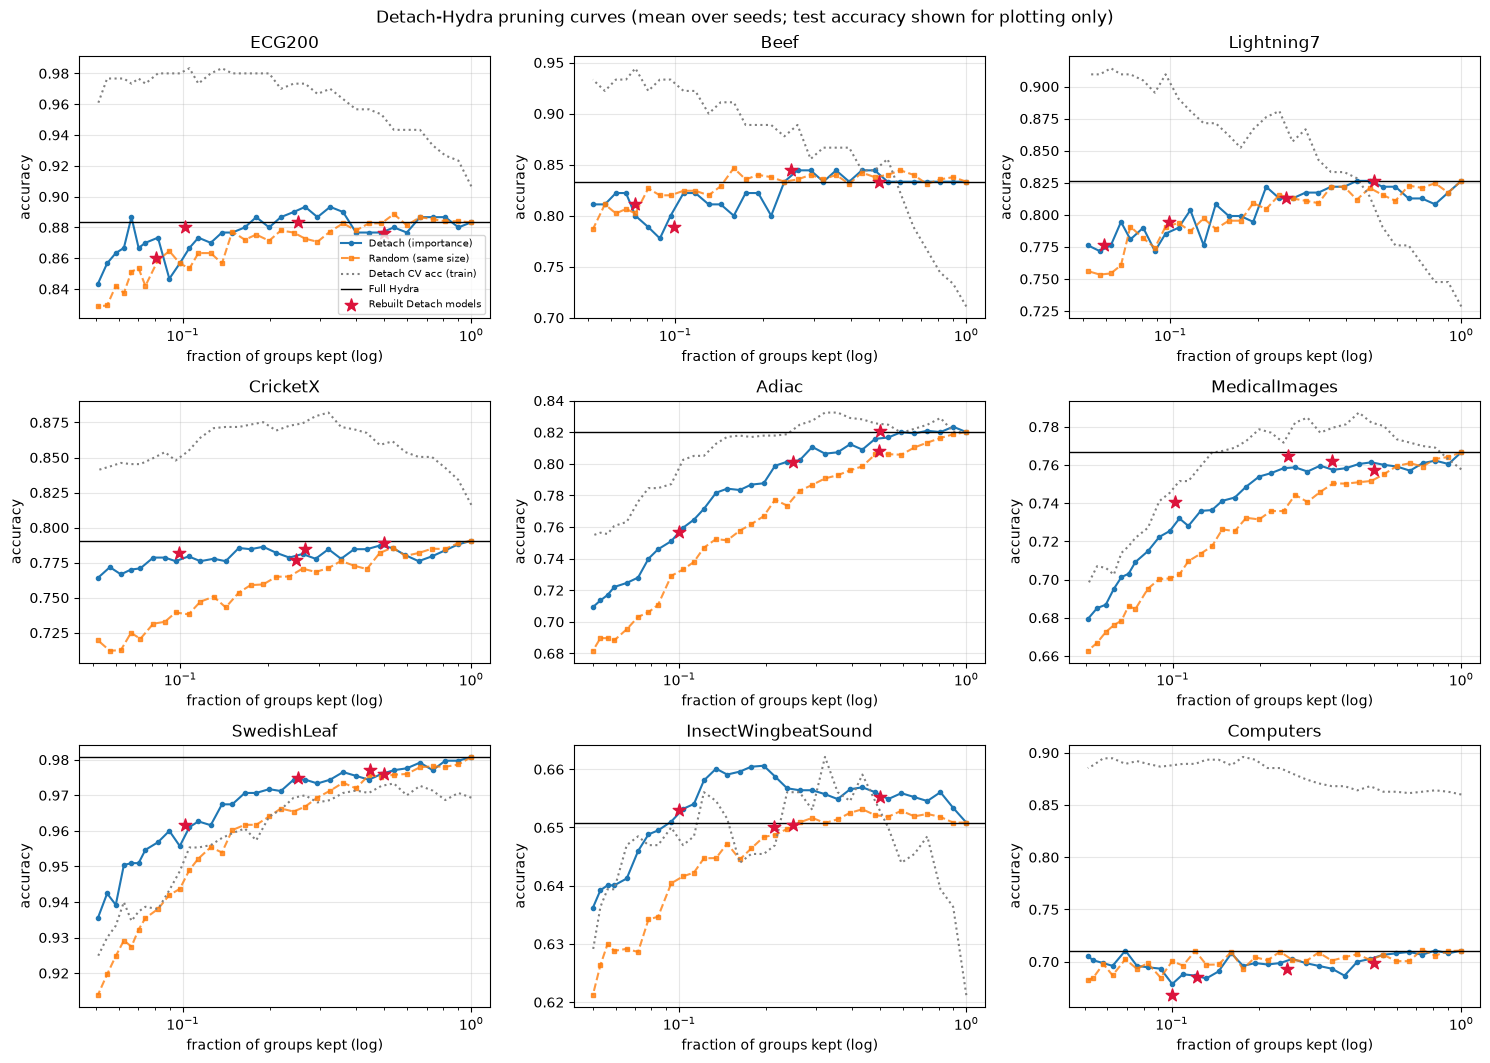

In [18]:
# ---- Figure 1: pruning curves (test accuracy is plot-only; never used for selection) ----
datasets = [d for d in PILOT_DATASETS if d in paths["dataset"].unique()]
ncols = 3
nrows = int(math.ceil(len(datasets) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.6 * nrows), squeeze=False)

for ax, ds in zip(axes.flat, datasets):
    p = paths[paths["dataset"] == ds].groupby("step").mean(numeric_only=True)
    ax.plot(p["frac_groups_kept"], p["test_acc_for_plot_only"], "o-", ms=3, label="Detach (importance)")
    ax.plot(p["frac_groups_kept"], p["random_test_acc_for_plot_only"], "s--", ms=3, alpha=0.8,
            label="Random (same size)")
    ax.plot(p["frac_groups_kept"], p["cv_acc"], ":", color="grey", label="Detach CV acc (train)")
    full_acc = pilot[(pilot["dataset"] == ds) & (pilot["method"] == "full")]["test_acc"].mean()
    ax.axhline(full_acc, color="black", lw=1, label="Full Hydra")
    rb = pilot[(pilot["dataset"] == ds) & pilot["method"].isin(["detach_selected", "detach_50",
                                                                 "detach_25", "detach_10"])]
    rb = rb.groupby("method")[["frac_groups_kept", "test_acc"]].mean()
    ax.scatter(rb["frac_groups_kept"], rb["test_acc"], marker="*", s=90, color="crimson", zorder=5,
               label="Rebuilt Detach models")
    ax.set_xscale("log")
    ax.set_title(ds)
    ax.set_xlabel("fraction of groups kept (log)")
    ax.set_ylabel("accuracy")
    ax.grid(alpha=0.3)

for ax in list(axes.flat)[len(datasets):]:
    ax.axis("off")
axes.flat[0].legend(fontsize=7, loc="lower right")
fig.suptitle("Detach-Hydra pruning curves (mean over seeds; test accuracy shown for plotting only)")
fig.tight_layout()
fig.savefig(FIG_DIR / "detach_hydra_pruning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

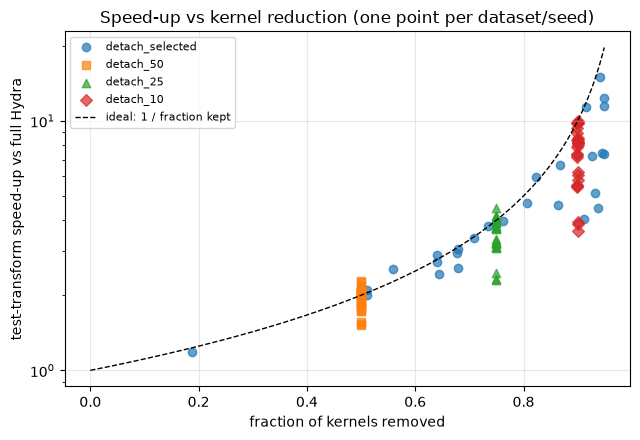

,count,mean,std,min,25%,50%,75%,max
method,,,,,,,,
detach_10,27.0,0.747,0.194,0.359,0.590,0.800,0.883,0.999
detach_25,27.0,0.884,0.143,0.577,0.805,0.930,0.996,1.115
detach_50,27.0,0.966,0.102,0.762,0.902,0.986,1.033,1.144
detach_selected,27.0,0.797,0.260,0.279,0.613,0.906,0.983,1.130


In [19]:
# ---- Figure 2: test-transform speed-up vs fraction of kernels removed ----
det = pilot[pilot["method"].isin(["detach_selected", "detach_50", "detach_25", "detach_10"])].copy()
det["frac_removed"] = 1 - det["frac_kernels_kept"]

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for m, marker in zip(["detach_selected", "detach_50", "detach_25", "detach_10"], ["o", "s", "^", "D"]):
    s = det[det["method"] == m]
    ax.scatter(s["frac_removed"], s["test_transform_speedup"], marker=marker, alpha=0.7, label=m)
xs = np.linspace(0, det["frac_removed"].max(), 200)
ax.plot(xs, 1 / (1 - xs), "k--", lw=1, label="ideal: 1 / fraction kept")
ax.set_xlabel("fraction of kernels removed")
ax.set_ylabel("test-transform speed-up vs full Hydra")
ax.set_yscale("log")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
ax.set_title("Speed-up vs kernel reduction (one point per dataset/seed)")
fig.tight_layout()
fig.savefig(FIG_DIR / "detach_hydra_speedup_vs_kernels.png", dpi=150, bbox_inches="tight")
plt.show()

det["speedup_efficiency"] = det["test_transform_speedup"] * det["frac_kernels_kept"]   # 1.0 = proportional
display(det.groupby("method")["speedup_efficiency"].describe().round(3))

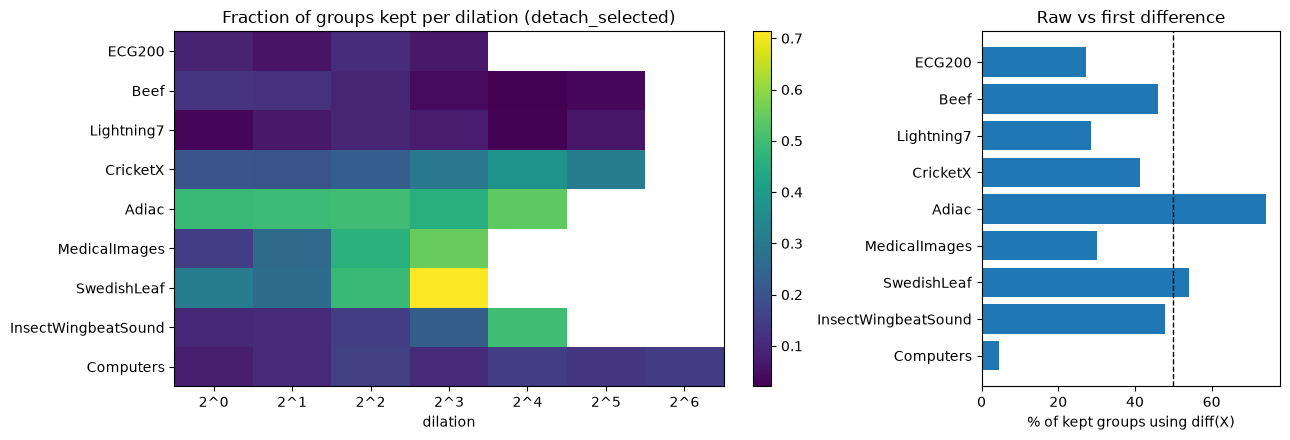

dilation_index,0,1,2,3,4,5,6
dataset,,,,,,,
ECG200,0.089,0.057,0.109,0.068,NaN,NaN,NaN
Beef,0.125,0.120,0.094,0.042,0.021,0.036,NaN
Lightning7,0.031,0.068,0.094,0.073,0.026,0.062,NaN
CricketX,0.203,0.198,0.229,0.297,0.375,0.312,NaN
Adiac,0.490,0.495,0.500,0.458,0.542,NaN,NaN
MedicalImages,0.146,0.260,0.464,0.552,NaN,NaN,NaN
SwedishLeaf,0.312,0.266,0.490,0.714,NaN,NaN,NaN
InsectWingbeatSound,0.099,0.104,0.146,0.224,0.500,NaN,NaN
Computers,0.078,0.104,0.151,0.104,0.146,0.130,0.141


,% kept groups on diff(X)
dataset,
ECG200,27.2
Beef,46.0
Lightning7,28.6
CricketX,41.3
Adiac,74.1
MedicalImages,30.2
SwedishLeaf,54.1
InsectWingbeatSound,47.7
Computers,4.5


In [20]:
# ---- Figure 3: which groups survive? (interpretability) ----
# Fraction of groups kept at each dilation index (each dilation has 2h = 64 groups), mean over seeds
by_dil = (kept_groups.groupby(["dataset", "seed", "dilation_index"])["kept"].mean()
          .groupby(["dataset", "dilation_index"]).mean().unstack())
by_dil = by_dil.reindex([d for d in PILOT_DATASETS if d in by_dil.index])

# Share of the kept groups that use the first difference (50% = no preference)
diff_share = (kept_groups[kept_groups["kept"]].groupby(["dataset", "seed"])["diff_index"].mean()
              .groupby("dataset").mean().reindex(by_dil.index))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [2, 1]})
im = ax1.imshow(by_dil.to_numpy(dtype=float), aspect="auto", cmap="viridis")
ax1.set_yticks(range(len(by_dil.index)), by_dil.index)
ax1.set_xticks(range(by_dil.shape[1]), [f"2^{i}" for i in by_dil.columns])
ax1.set_xlabel("dilation")
ax1.set_title("Fraction of groups kept per dilation (detach_selected)")
fig.colorbar(im, ax=ax1, fraction=0.03)

ax2.barh(diff_share.index, diff_share.values * 100)
ax2.axvline(50, color="black", lw=1, ls="--")
ax2.set_xlabel("% of kept groups using diff(X)")
ax2.set_title("Raw vs first difference")
ax2.invert_yaxis()
fig.tight_layout()
fig.savefig(FIG_DIR / "detach_hydra_kept_groups.png", dpi=150, bbox_inches="tight")
plt.show()

display(by_dil.round(3))
display((diff_share * 100).round(1).rename("% kept groups on diff(X)").to_frame())

In [21]:
# ---- Table 2: win / draw / loss of detach_selected vs each comparator ----
# NOTE: 9 datasets x 3 seeds is a pilot. These counts are descriptive only - NO significance claims.
def wdl(a, b, tol=1e-9):
    d = a - b
    return int((d > tol).sum()), int((d.abs() <= tol).sum()), int((d < -tol).sum()), float(d.mean() * 100)

per_ds = pilot.groupby(["dataset", "method"])["test_acc"].mean().unstack()
per_run = acc   # (dataset, seed) x method

rows = []
for other in ["full", "random_same_size", "small_g", "max_only"]:
    w, d, l, m = wdl(per_ds["detach_selected"], per_ds[other])
    rw, rd, rl, _ = wdl(per_run["detach_selected"], per_run[other])
    rows.append({"detach_selected vs": other,
                 "datasets W/D/L": f"{w}/{d}/{l}",
                 "runs W/D/L": f"{rw}/{rd}/{rl}",
                 "mean acc diff (pp)": round(m, 2)})
wdl_table = pd.DataFrame(rows)
display(wdl_table)
print(f"Pilot only ({pilot['dataset'].nunique()} datasets x {pilot['seed'].nunique()} seeds): "
      "descriptive counts, no significance testing.")

,detach_selected vs,datasets W/D/L,runs W/D/L,mean acc diff (pp)
0,full,0/0/9,5/3/19,-1.64
1,random_same_size,8/0/1,19/0/8,0.48
2,small_g,5/0/4,15/2/10,-0.21
3,max_only,4/0/5,11/4/12,-1.09


Pilot only (9 datasets x 3 seeds): descriptive counts, no significance testing.


## 8. Go / no-go

The next cell computes each criterion from the saved results. **The verdict markdown below it must be written from those printed numbers after the notebook has been run.** It is deliberately left as a template rather than pre-filled.

In [22]:
n_ds = len(summary)
sel = pilot[pilot["method"] == "detach_selected"]
mean_frac = sel["frac_groups_kept"].mean()
mean_diff_pp = summary["detach_minus_full_pp"].mean()
c1 = (mean_frac <= 0.5) and (mean_diff_pp >= -1.0)

w_rand = int((per_ds["detach_selected"] > per_ds["random_same_size"] + 1e-9).sum())
w_small = int((per_ds["detach_selected"] > per_ds["small_g"] + 1e-9).sum())
c2 = (w_rand > n_ds / 2) and (w_small > n_ds / 2)

eff = det[det["method"] == "detach_selected"]["speedup_efficiency"]
c3 = 0.6 <= eff.median() <= 1.4

print(f"Q1  detach_selected keeps {mean_frac:.1%} of groups on average (median {sel['frac_groups_kept'].median():.1%}),")
print(f"    mean accuracy change vs full = {mean_diff_pp:+.2f} pp  ->  {'YES' if c1 else 'NO'}"
      " (criterion: <= 50% groups and within 1 pp)")
print(f"Q2  beats random_same_size on {w_rand}/{n_ds} datasets, beats small_g on {w_small}/{n_ds}"
      f"  ->  {'YES' if c2 else 'NO'} (criterion: most datasets for both)")
print(f"Q3  speed-up x fraction-of-kernels-kept: median {eff.median():.2f} (1.0 = exactly proportional),"
      f" range {eff.min():.2f}-{eff.max():.2f}  ->  {'YES' if c3 else 'NO'} (criterion: median 0.6-1.4)")

worst = summary.sort_values("detach_minus_full_pp").head(3)
print("\nDatasets where Detach loses most vs full:")
display(worst[["full_acc", "detach_acc", "random_acc", "small_g_acc", "detach_frac_kernels_kept",
               "detach_minus_full_pp"]].round(4))

if c1 and c2 and c3:
    print("DRAFT RECOMMENDATION: GO - scale up to the 40 development datasets, then all 112.")
elif c1 and c3 and not c2:
    print("DRAFT RECOMMENDATION: NO-GO as a method contribution - pruning works but does not beat "
          "random / smaller-g at equal size (it behaves like a hyperparameter change).")
else:
    print("DRAFT RECOMMENDATION: MIXED - inspect the per-dataset table and curves before deciding.")

Q1  detach_selected keeps 23.5% of groups on average (median 19.3%),
    mean accuracy change vs full = -1.64 pp  ->  NO (criterion: <= 50% groups and within 1 pp)
Q2  beats random_same_size on 8/9 datasets, beats small_g on 5/9  ->  YES (criterion: most datasets for both)
Q3  speed-up x fraction-of-kernels-kept: median 0.91 (1.0 = exactly proportional), range 0.28-1.13  ->  YES (criterion: median 0.6-1.4)

Datasets where Detach loses most vs full:


,full_acc,detach_acc,random_acc,small_g_acc,detach_frac_kernels_kept,detach_minus_full_pp
dataset,,,,,,
Lightning7,0.8265,0.7763,0.7607,0.7717,0.0590,-5.0228
Computers,0.7107,0.6853,0.7123,0.7000,0.1220,-2.5333
ECG200,0.8833,0.8600,0.8553,0.8633,0.0807,-2.3333


DRAFT RECOMMENDATION: MIXED - inspect the per-dataset table and curves before deciding.


### Verdict (fill in from the numbers above after running)

- **Q1: ≤ 50% of groups kept and within 1 pp of full Hydra?** _…_
- **Q2: better than `random_same_size` and `small_g` at equal size on most datasets?** _…_
- **Q3: test-transform speed-up roughly proportional to the kernel reduction?** _…_
- **Datasets that behave differently, with a likely reason:** _…_
- **Recommendation (scale to 40 / 112 datasets, or not):** _…_

*Caveats:*

- Pilot only: 9 datasets × 3 seeds, so there are no significance claims.
- Single default UCR split, not the paper's 30 resamples.
- `SparseScaler` statistics inside the CV come from the full training set (small leak, train-only).
- The ridge alpha is fixed during the elimination path. The rebuilt models re-select alpha.